<a href="https://colab.research.google.com/github/ralucapestritu/ML_Seminar_Pestritu-BoborocRaluca/blob/main/tema_laborator_3_ml_Pestritu-Boboroc_Raluca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [11]:
# TODO 1.1 — procentul de valori lipsă pe coloană

missing_percent=(df.isnull().mean()*100).sort_values(ascending=False)
print(missing_percent)


# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă

df=df.drop(missing_percent[missing_percent>50].index,axis=1)
df.head()



deck        77.216611
age         19.865320
embarked     0.224467
sex          0.000000
pclass       0.000000
survived     0.000000
fare         0.000000
dtype: float64


,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [12]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy()

df['age']=df['age'].fillna(df['age'].median())
df['embarked']=df['embarked'].fillna(df['embarked'].mode()[0])

# TODO 2.2 — verificare + comparație deviație standard
print("valori lipsa dupa imputare:")
print(df.isnull().sum())

print("deviatia standard inainte:",age_inainte.std())
print("deviatia standard dupa:",df['age'].std())


valori lipsa dupa imputare:
survived    0
pclass      0
sex         0
age         0
fare        0
embarked    0
dtype: int64
deviatia standard inainte: 14.526497332334044
deviatia standard dupa: 13.019696550973194


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

4.787316519674893
0.3949280095189306


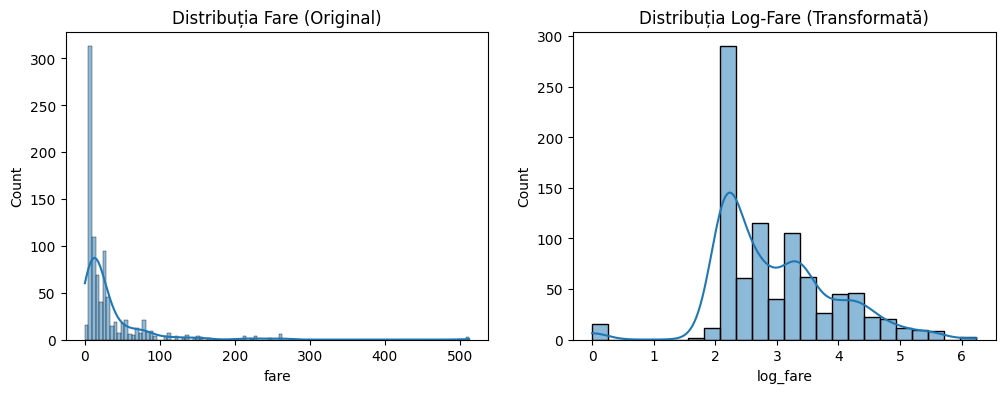

In [13]:
# TODO 3.1 — skewness fare
import numpy as np
print(df['fare'].skew())


# TODO 3.2 — coloana log_fare + skewness
df['log_fare']=np.log1p(df['fare'])
print(df['log_fare'].skew())

# TODO 3.3 — histograme
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# TODO 3.3 — două histograme
sns.histplot(df['fare'], ax=axes[0], kde=True)
axes[0].set_title('Distribuția Fare (Original)')

sns.histplot(df['log_fare'], ax=axes[1], kde=True)
axes[1].set_title('Distribuția Log-Fare (Transformată)')

plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [14]:
# TODO 4.1 — limite IQR + număr de outlieri
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlieri = df[(df['fare'] < lower_bound) | (df['fare'] > upper_bound)]
print(f"Număr de outlieri: {len(outlieri)}")

# TODO 4.2 — fare_capped (clip) + maxim înainte/după
print(f"Maxim înainte: {df['fare'].max()}")

df['fare_capped'] = df['fare'].clip(lower=lower_bound, upper=upper_bound)

print(f"Maxim după: {df['fare_capped'].max()}")

Număr de outlieri: 116
Maxim înainte: 512.3292
Maxim după: 65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [15]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
df=pd.get_dummies(df,columns=['sex','embarked'],drop_first=True,dtype=int)

# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std

scaler=StandardScaler()
df[['age','fare_capped']]=scaler.fit_transform(df[['age','fare_capped']])

print("media dupa standardizare:\n",df[['age','fare_capped']].mean())
print("deviatia standard dupa standardizare:\n",df[['age','fare_capped']].std())


media dupa standardizare:
 age            2.272780e-16
fare_capped    9.968332e-17
dtype: float64
deviatia standard dupa standardizare:
 age            1.000562
fare_capped    1.000562
dtype: float64


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

*Răspunsul tău:* Am imputat coloana age deoarece are un procent mic de valori lipsa (aproximativ 20%) si reprezinta un factor critic pentru sansele de supravietuire ("femeile si copiii primii"), dar coloana deck a fost eliminata din cauza numarului masiv de date lipsa (aproximativ 77%) si a redundantei sale, informatia despre pozitia pe nava fiind deja reflectata de clasa biletului (pclass).